In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [66]:
# Load the dataset
df = pd.read_csv('D:\Dormant Merchant Detection\dataset_merchant.csv')
df.head()

,id,mcc,january,february,march,april,may,june,july,august,september,october,november,december,transactions,tr_amount,scale,reg_date,geo_region,dormant_merchant
0,1,8,1,1,1,0,1,1,0,0,0,1,1,1,137.0,157782.36,small,6/26/2018,chenkaladi,0
1,2,2,1,1,1,1,0,0,0,1,1,0,1,1,1458.0,1068065.94,large,11/28/2020,monaragala,0
2,3,13,0,0,1,0,0,1,1,0,1,1,1,0,422.0,248688.24,small,8/24/2018,batticaloa,0
3,4,10,1,0,0,1,1,0,1,0,0,0,1,1,121.0,258894.38,small,8/11/2018,ambalangoda,0
4,5,11,0,0,1,1,0,0,1,1,1,0,0,0,176.0,764392.63,medium,5/19/2018,puliyankulam,1


In [67]:
# Display basic information about the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1155 entries, 0 to 1154
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                1155 non-null   int64  
 1   mcc               1155 non-null   int64  
 2   january           1155 non-null   int64  
 3   february          1155 non-null   int64  
 4   march             1155 non-null   int64  
 5   april             1155 non-null   int64  
 6   may               1155 non-null   int64  
 7   june              1155 non-null   int64  
 8   july              1155 non-null   int64  
 9   august            1155 non-null   int64  
 10  september         1155 non-null   int64  
 11  october           1155 non-null   int64  
 12  november          1155 non-null   int64  
 13  december          1155 non-null   int64  
 14  transactions      1138 non-null   float64
 15  tr_amount         1145 non-null   float64
 16  scale             1140 non-null   object 


In [68]:
# Check for null values
null_values = df.isnull().sum()

In [69]:
# Display the null values
print("Null Values in Each Column:")
print(null_values)

Null Values in Each Column:
id                   0
mcc                  0
january              0
february             0
march                0
april                0
may                  0
june                 0
july                 0
august               0
september            0
october              0
november             0
december             0
transactions        17
tr_amount           10
scale               15
reg_date             0
geo_region           0
dormant_merchant     0
dtype: int64


In [70]:
null_values = df.isnull().sum()
print("Null Values in Each Column:")
print(null_values)

# Drop rows with missing values
df = df.dropna()

# Display the shape of the DataFrame after removing missing values
print("Shape of DataFrame after removing missing values:", df.shape)

Null Values in Each Column:
id                   0
mcc                  0
january              0
february             0
march                0
april                0
may                  0
june                 0
july                 0
august               0
september            0
october              0
november             0
december             0
transactions        17
tr_amount           10
scale               15
reg_date             0
geo_region           0
dormant_merchant     0
dtype: int64
Shape of DataFrame after removing missing values: (1114, 20)


In [71]:
# Handle categorical features
le = LabelEncoder()
df['scale'] = le.fit_transform(df['scale'])

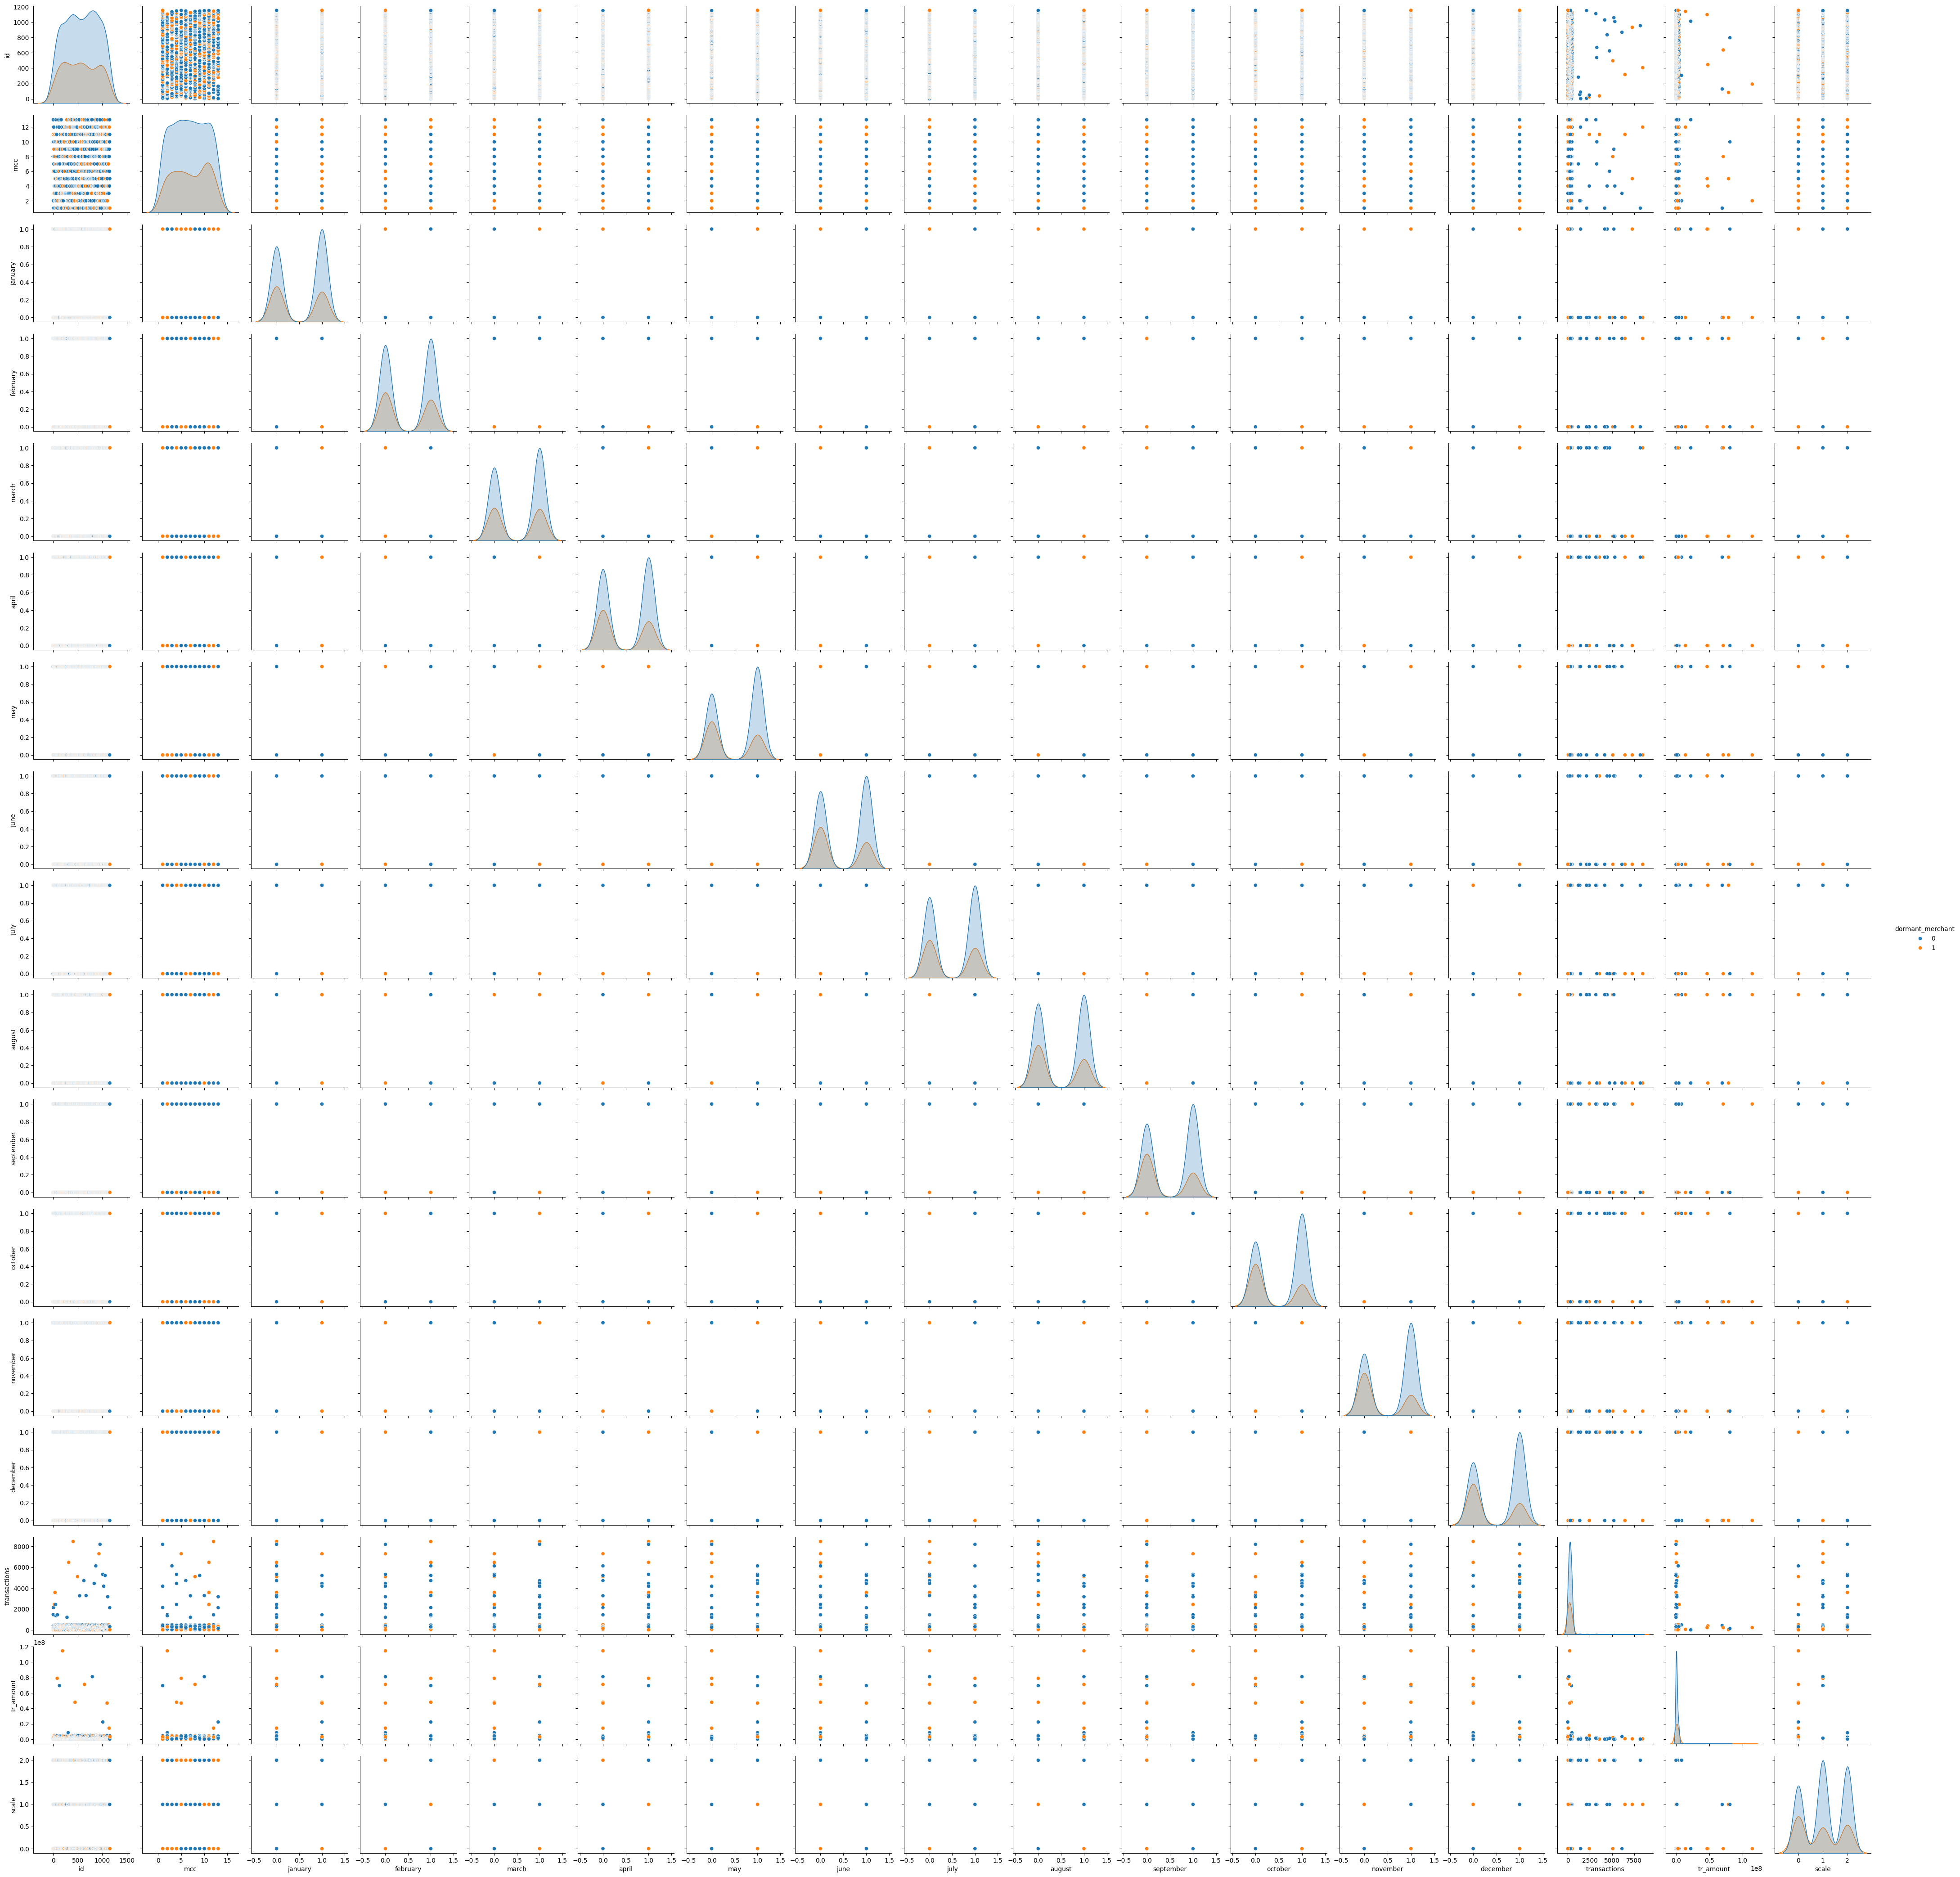

In [72]:
# Explore the data visually
sns.pairplot(df, hue='dormant_merchant')
plt.show()

In [73]:
# One-hot encode 'geo_region'
df = pd.get_dummies(df, columns=['geo_region'], prefix='region')

In [74]:
# Handle datetime feature
df['reg_date'] = pd.to_datetime(df['reg_date'])
df['registered_year'] = df['reg_date'].dt.year
df['registered_month'] = df['reg_date'].dt.month
df['registered_day'] = df['reg_date'].dt.day
df = df.drop(columns=['reg_date'])

In [75]:
df.head()

,id,mcc,january,february,march,april,may,june,july,august,...,region_tissamaharama,region_trincomalee,region_udugama,region_uhana,region_valachchenai,region_vavuniya,region_vellankulam,registered_year,registered_month,registered_day
0,1,8,1,1,1,0,1,1,0,0,...,False,False,False,False,False,False,False,2018,6,26
1,2,2,1,1,1,1,0,0,0,1,...,False,False,False,False,False,False,False,2020,11,28
2,3,13,0,0,1,0,0,1,1,0,...,False,False,False,False,False,False,False,2018,8,24
3,4,10,1,0,0,1,1,0,1,0,...,False,False,False,False,False,False,False,2018,8,11
4,5,11,0,0,1,1,0,0,1,1,...,False,False,False,False,False,False,False,2018,5,19


In [76]:
df.shape

(1114, 117)

In [77]:
null1 = df['tr_amount'].isnull().sum()
null1

0

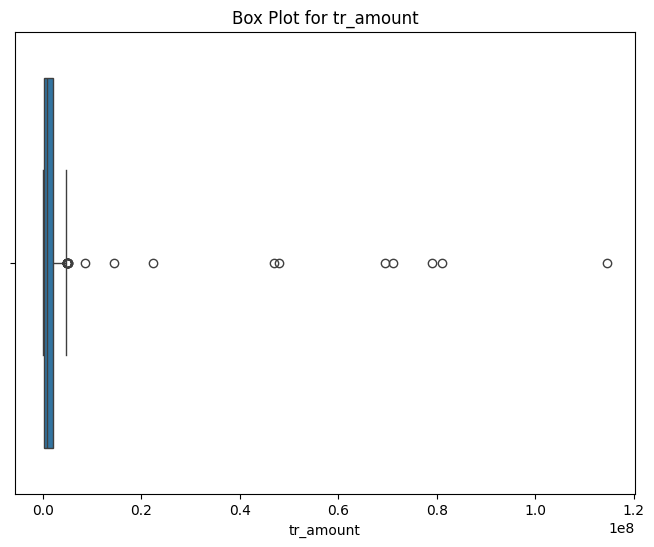

In [78]:
# Box plot for 'tr_amount'
plt.figure(figsize=(8, 6))
sns.boxplot(x=df['tr_amount'])
plt.title('Box Plot for tr_amount')
plt.show()

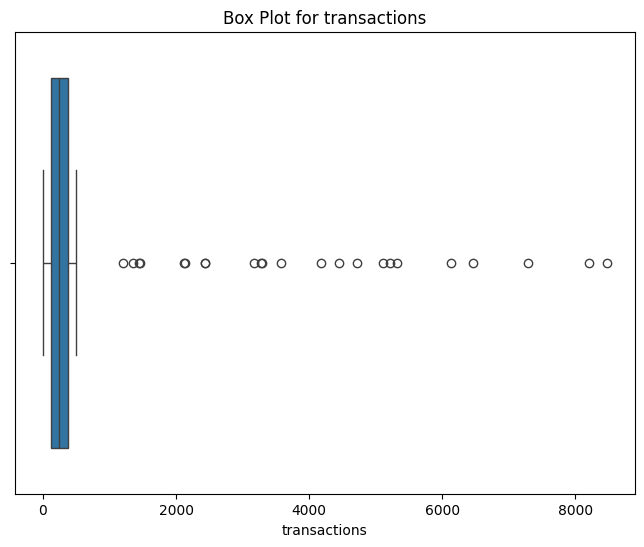

In [79]:
# Box plot for 'transactions'
plt.figure(figsize=(8, 6))
sns.boxplot(x=df['transactions'])
plt.title('Box Plot for transactions')
plt.show()

In [80]:
# Handle outliers
outlier_columns = ['transactions', 'tr_amount']
for col in outlier_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df[col] = np.where((df[col] < lower_bound) | (df[col] > upper_bound), df[col].median(), df[col])

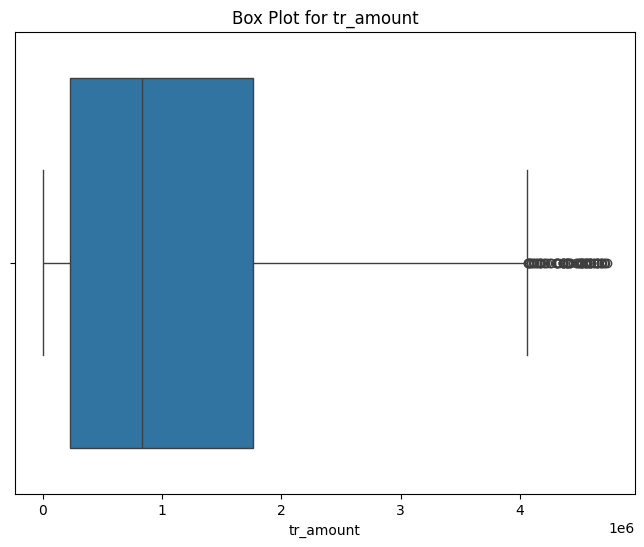

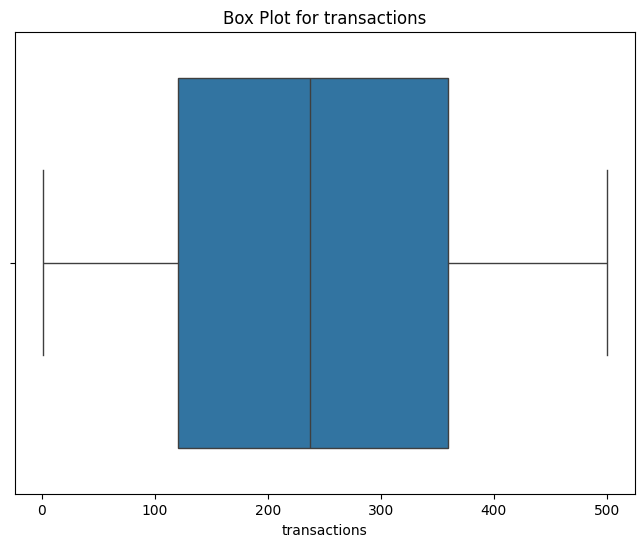

In [81]:
# Box plot for 'tr_amount'
plt.figure(figsize=(8, 6))
sns.boxplot(x=df['tr_amount'])
plt.title('Box Plot for tr_amount')
plt.show()

# Box plot for 'transactions'
plt.figure(figsize=(8, 6))
sns.boxplot(x=df['transactions'])
plt.title('Box Plot for transactions')
plt.show()

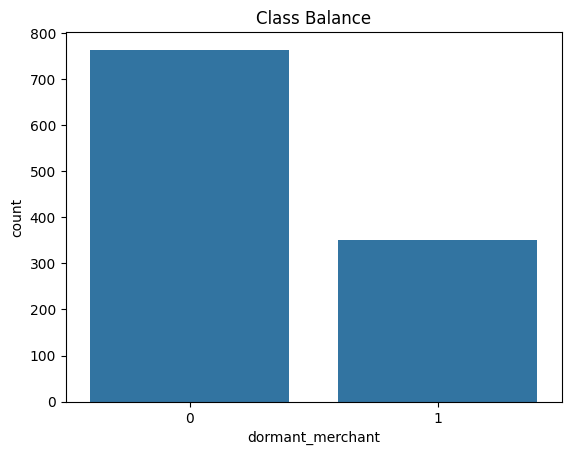

In [82]:
# Display class balance
sns.countplot(x='dormant_merchant', data=df)
plt.title('Class Balance')
plt.show()

In [83]:
# Display frequency of dormant and not values
print("Frequency of Dormant and Not values:")
print(df['dormant_merchant'].value_counts())

Frequency of Dormant and Not values:
dormant_merchant
0    764
1    350
Name: count, dtype: int64


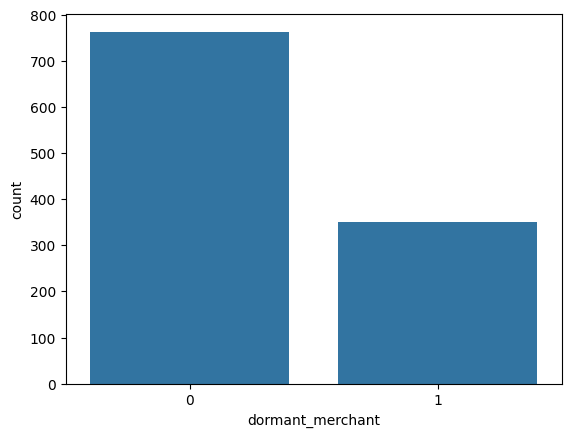

In [84]:
# Visualize the distribution of the target variable
sns.countplot(x='dormant_merchant', data=df)
plt.show()

In [85]:
# Split the data into features and target variable
X = df.drop(columns=['dormant_merchant'])
y = df['dormant_merchant']

In [86]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [87]:
# Standardize the features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [88]:
# Feature Selection Algorithm (Using Random Forest for feature importance)
rf_model = RandomForestClassifier()
rf_model.fit(X_train, y_train)

feature_importance = pd.Series(rf_model.feature_importances_, index=X.columns)
sorted_feature_importance = feature_importance.sort_values(ascending=False)

In [89]:
# Display sorted feature importance
print("Feature Importance:")
print(sorted_feature_importance)

Feature Importance:
transactions           0.105685
tr_amount              0.085237
id                     0.068925
registered_day         0.055783
december               0.050622
                         ...   
region_talaimannar     0.000657
region_monaragala      0.000565
region_kalpitiya       0.000529
region_horuwupotana    0.000397
region_haputale        0.000326
Length: 116, dtype: float64


In [90]:
# Define models and parameter grids for hyperparameter tuning
models = {
    'Logistic Regression': (LogisticRegression(), {'C': [0.001, 0.01, 0.1, 1, 10, 100], 'penalty': ['l1', 'l2']}),
    'Random Forest': (RandomForestClassifier(), {'n_estimators': [50, 100, 200], 'max_depth': [None, 10, 20], 'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4]}),
    'Support Vector Machine': (SVC(), {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf', 'poly']}),
    'Naive Bayes': (GaussianNB(), {}),
    'Artificial Neural Network': (MLPClassifier(), {'hidden_layer_sizes': [(50,), (100,), (50, 50)], 'activation': ['relu', 'tanh'], 'alpha': [0.0001, 0.001, 0.01]})
}

In [91]:
# Perform hyperparameter tuning and 10-fold cross-validation for each model
for name, (model, param_grid) in models.items():
    print(f"\nHyperparameter Tuning for {name}:")
    
    # Instantiate GridSearchCV
    grid_search = GridSearchCV(estimator=model, param_grid=param_grid, scoring='accuracy', cv=10)
    
    # Fit the model to the training data
    grid_search.fit(X_train, y_train)
    
    # Display the best hyperparameters
    print("Best Hyperparameters:", grid_search.best_params_)
    
    # Get the best model
    best_model = grid_search.best_estimator_
    
    # Evaluate the best model on the test set
    y_pred = best_model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    print(f"Accuracy of the Best {name} Model on Test Set:", accuracy)



Hyperparameter Tuning for Logistic Regression:


C:\Anaconda_3\envs\ML\lib\site-packages\sklearn\model_selection\_validation.py:425: FitFailedWarning: 
60 fits failed out of a total of 120.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
60 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Anaconda_3\envs\ML\lib\site-packages\sklearn\model_selection\_validation.py", line 729, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Anaconda_3\envs\ML\lib\site-packages\sklearn\base.py", line 1152, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "C:\Anaconda_3\envs\ML\lib\site-packages\sklearn\linear_model\_logistic.py", line 1169, in fit
    solver = _check_solver(self.solver, self.penalty, self.dual)
  File "C:

Best Hyperparameters: {'C': 0.01, 'penalty': 'l2'}
Accuracy of the Best Logistic Regression Model on Test Set: 0.7623318385650224

Hyperparameter Tuning for Random Forest:
Best Hyperparameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
Accuracy of the Best Random Forest Model on Test Set: 0.7982062780269058

Hyperparameter Tuning for Support Vector Machine:
Best Hyperparameters: {'C': 10, 'kernel': 'linear'}
Accuracy of the Best Support Vector Machine Model on Test Set: 0.7713004484304933

Hyperparameter Tuning for Naive Bayes:
Best Hyperparameters: {}
Accuracy of the Best Naive Bayes Model on Test Set: 0.47533632286995514

Hyperparameter Tuning for Artificial Neural Network:


C:\Anaconda_3\envs\ML\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Anaconda_3\envs\ML\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Anaconda_3\envs\ML\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Anaconda_3\envs\ML\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Anaconda_3\envs\ML\lib\site-packages\sklearn\neural_network\_multilayer_perceptro

Best Hyperparameters: {'activation': 'relu', 'alpha': 0.01, 'hidden_layer_sizes': (50,)}
Accuracy of the Best Artificial Neural Network Model on Test Set: 0.7488789237668162


C:\Anaconda_3\envs\ML\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(



Logistic Regression Cross-Validation Scores:
[0.78888889 0.75280899 0.75280899 0.74157303 0.78651685 0.75280899
 0.7752809  0.74157303 0.74157303 0.73033708]
Mean Accuracy: 0.7564

Random Forest Cross-Validation Scores:
[0.77777778 0.85393258 0.79775281 0.78651685 0.82022472 0.79775281
 0.82022472 0.76404494 0.79775281 0.84269663]
Mean Accuracy: 0.8059

Support Vector Machine Cross-Validation Scores:
[0.75555556 0.75280899 0.70786517 0.74157303 0.73033708 0.69662921
 0.75280899 0.71910112 0.73033708 0.7752809 ]
Mean Accuracy: 0.7362

Naive Bayes Cross-Validation Scores:
[0.45555556 0.40449438 0.4494382  0.48314607 0.52808989 0.41573034
 0.4494382  0.43820225 0.49438202 0.51685393]
Mean Accuracy: 0.4635


C:\Anaconda_3\envs\ML\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Anaconda_3\envs\ML\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Anaconda_3\envs\ML\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Anaconda_3\envs\ML\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Anaconda_3\envs\ML\lib\site-packages\sklearn\neural_network\_multilayer_perceptro


Artificial Neural Network Cross-Validation Scores:
[0.8        0.76404494 0.79775281 0.7752809  0.78651685 0.75280899
 0.75280899 0.75280899 0.78651685 0.73033708]
Mean Accuracy: 0.7699


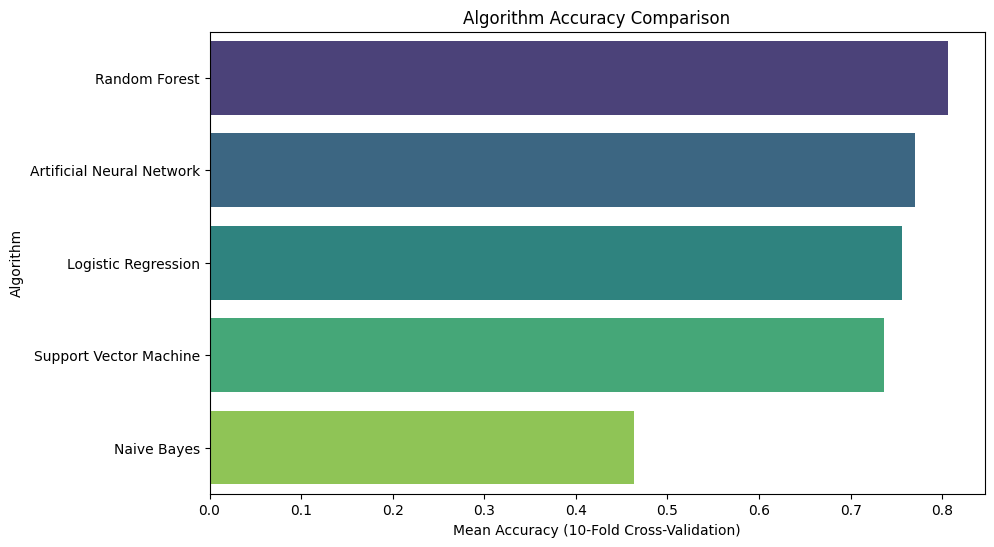

In [92]:
# Visualize the performance of each algorithm
model_accuracies = {}
for name, (model, _) in models.items():
    # Perform cross-validation
    cv_scores = cross_val_score(model, X_train, y_train, cv=10, scoring='accuracy')
    model_accuracies[name] = cv_scores.mean()
    
    # Print cross-validation results
    print(f"\n{name} Cross-Validation Scores:")
    print(cv_scores)
    print(f"Mean Accuracy: {cv_scores.mean():.4f}")




C:\Users\Thilaksha Lakshan\AppData\Local\Temp\ipykernel_8796\4158291954.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Accuracy', y='Algorithm', data=model_df.sort_values(by='Accuracy', ascending=False), palette='viridis')


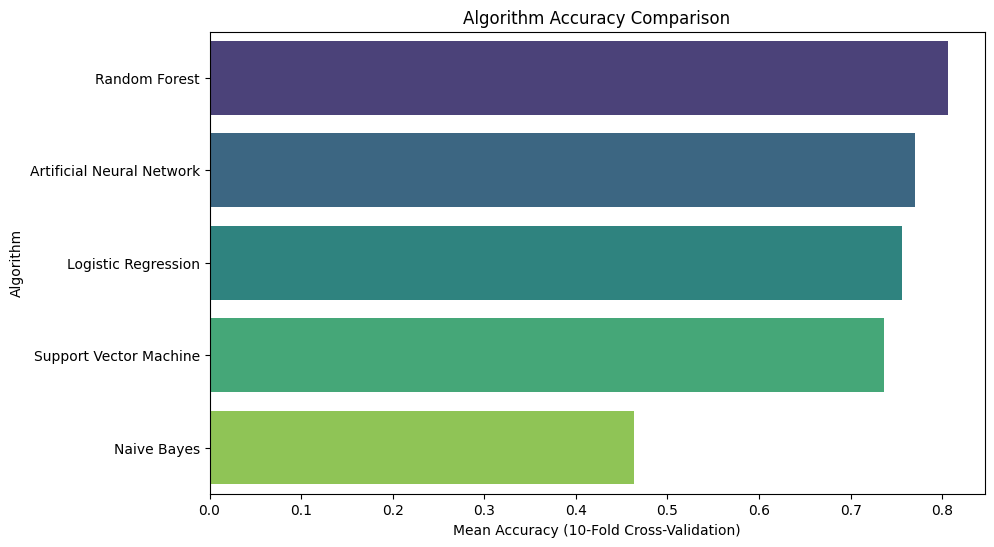

In [96]:
# Visualize the performance of each algorithm
model_df = pd.DataFrame(list(model_accuracies.items()), columns=['Algorithm', 'Accuracy'])
plt.figure(figsize=(10, 6))
sns.barplot(x='Accuracy', y='Algorithm', data=model_df.sort_values(by='Accuracy', ascending=False), palette='viridis')
plt.title('Algorithm Accuracy Comparison')
plt.xlabel('Mean Accuracy (10-Fold Cross-Validation)')
plt.ylabel('Algorithm')
plt.show()

In [93]:
for name, (model, _) in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    print(f'\n{name} Accuracy:', accuracy)
    print('Confusion Matrix:')
    print(confusion_matrix(y_test, y_pred))
    print('Classification Report:')
    print(classification_report(y_test, y_pred))



Logistic Regression Accuracy: 0.7713004484304933
Confusion Matrix:
[[135  24]
 [ 27  37]]
Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.85      0.84       159
           1       0.61      0.58      0.59        64

    accuracy                           0.77       223
   macro avg       0.72      0.71      0.72       223
weighted avg       0.77      0.77      0.77       223


Random Forest Accuracy: 0.7982062780269058
Confusion Matrix:
[[154   5]
 [ 40  24]]
Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.97      0.87       159
           1       0.83      0.38      0.52        64

    accuracy                           0.80       223
   macro avg       0.81      0.67      0.69       223
weighted avg       0.80      0.80      0.77       223


Support Vector Machine Accuracy: 0.7354260089686099
Confusion Matrix:
[[142  17]
 [ 42  22]]
Classification Report:
       

C:\Anaconda_3\envs\ML\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [94]:
# Train the best model on the entire dataset
best_model_name = 'Random Forest'  # Update with the best model name obtained during hyperparameter tuning
best_model, best_params = models[best_model_name]

# Extract the best hyperparameters
final_best_model = best_model.set_params(**best_params)

# Manually set 'max_depth' to its best value
final_best_model.set_params(max_depth=20, min_samples_leaf=1, min_samples_split=5, n_estimators=200)  # Update with the best values obtained during hyperparameter tuning

# Train the final best model on the entire dataset
final_best_model.fit(X, y)


RandomForestClassifier(max_depth=20, min_samples_split=5, n_estimators=200)

In [95]:
# Assuming 'new_data' is your new dataset (similarly preprocessed)
new_data = pd.read_csv('D:\\Dormant Merchant Detection\\new_data.csv')

# Drop rows with missing values
new_data = new_data.dropna()
# Standardize features using the same scaler used for training
new_data_scaled = scaler.transform(new_data)

# Predictions for the new data
predictions = final_best_model.predict(new_data_scaled)

# Display the predictions for the new data
print("Predictions for New Data:")
print(predictions)

Predictions for New Data:
[1 1 1 1 1 1 1 1 1 1]


C:\Anaconda_3\envs\ML\lib\site-packages\sklearn\base.py:465: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
